In [1]:
!pip -q install mne

import os
import urllib.request
import re
import mne

# 1. İndirilecek dosyaların listesi ve temel adres
base_url = "https://physionet.org/files/chbmit/1.0.0/"
files_to_download = [
    "chb01/chb01_03.edf", "chb01/chb01-summary.txt",
    "chb02/chb02_16.edf", "chb02/chb02-summary.txt",
    "chb03/chb03_01.edf", "chb03/chb03-summary.txt"
]

# 2. Dosyaları indirme döngüsü
for filepath in files_to_download:
    os.makedirs(os.path.dirname(filepath), exist_ok=True) # Klasörleri (chb01 vb.) oluştur
    if not os.path.exists(filepath):
        url = base_url + filepath
        print(f"İndiriliyor: {filepath} ...")
        urllib.request.urlretrieve(url, filepath)

# 3. İşlenecek kayıtların listesi
records = [
    {"edf": "chb01/chb01_03.edf", "summary": "chb01/chb01-summary.txt", "fname": "chb01_03.edf"},
    {"edf": "chb02/chb02_16.edf", "summary": "chb02/chb02-summary.txt", "fname": "chb02_16.edf"},
    {"edf": "chb03/chb03_01.edf", "summary": "chb03/chb03-summary.txt", "fname": "chb03_01.edf"}
]

# 4. Kayıtları sırayla okuma ve nöbet saatlerini çıkarma
for rec in records:
    print(f"\n{'-'*10} Kayıt: {rec['fname']} {'-'*10}")

    # EDF dosyasını MNE ile yükle
    raw = mne.io.read_raw_edf(rec['edf'], preload=True, verbose=False)
    fs = raw.info['sfreq']
    n_chan = raw.info['nchan']
    ch_names = raw.info['ch_names']
    duration = raw.times[-1] # Son zaman damgası (saniye cinsinden)

    print(f"Örnekleme Frekansı (fs): {fs} Hz")
    print(f"Kanal Sayısı: {n_chan}")
    print(f"Süre: {duration:.2f} saniye")
    print(f"Kanallar: {ch_names}")

    # Summary dosyasını okuma
    with open(rec['summary'], 'r') as f:
        content = f.read()

    # Regex ile sadece bu dosyaya ait metin bloğunu (File Name: chb01_03.edf) yakalama.
    # (Sonraki 'File Name:' kelimesine ya da dosya sonuna kadar olan kısmı alır)
    pattern_block = rf"File Name:\s*{re.escape(rec['fname'])}\s*(.*?)(?=File Name:|$)"
    match_block = re.search(pattern_block, content, re.DOTALL)

    if match_block:
        block_text = match_block.group(1) # Sadece ilgili kaydın summary bilgisi

        # Nöbet başlangıç ve bitiş zamanlarını dinamik olarak yakalama
        start_pattern = r'Seizure(?:\s+\d+)?\s+Start Time:\s*(\d+)'
        end_pattern = r'Seizure(?:\s+\d+)?\s+End Time:\s*(\d+)'

        starts = re.findall(start_pattern, block_text)
        ends = re.findall(end_pattern, block_text)

        if starts and ends:
            for s, e in zip(starts, ends):
                print(f"--> NÖBET TESPİT EDİLDİ: Başlangıç: {s} sn, Bitiş: {e} sn")
        else:
            print("--> Bu kayıtta nöbet tespit edilmedi.")
    else:
        print("--> Summary dosyasında bu kayda ait blok bulunamadı.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 32.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
İndiriliyor: chb01/chb01_03.edf ...
İndiriliyor: chb01/chb01-summary.txt ...
İndiriliyor: chb02/chb02_16.edf ...
İndiriliyor: chb02/chb02-summary.txt ...
İndiriliyor: chb03/chb03_01.edf ...
İndiriliyor: chb03/chb03-summary.txt ...

---------- Kayıt: chb01_03.edf ----------


/tmp/ipykernel_1880/4180800638.py:36: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(rec['edf'], preload=True, verbose=False)


Örnekleme Frekansı (fs): 256.0 Hz
Kanal Sayısı: 23
Süre: 3600.00 saniye
Kanallar: ['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2', 'FZ-CZ', 'CZ-PZ', 'P7-T7', 'T7-FT9', 'FT9-FT10', 'FT10-T8', 'T8-P8-1']
--> NÖBET TESPİT EDİLDİ: Başlangıç: 2996 sn, Bitiş: 3036 sn

---------- Kayıt: chb02_16.edf ----------
Örnekleme Frekansı (fs): 256.0 Hz
Kanal Sayısı: 23
Süre: 959.00 saniye
Kanallar: ['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2', 'FZ-CZ', 'CZ-PZ', 'P7-T7', 'T7-FT9', 'FT9-FT10', 'FT10-T8', 'T8-P8-1']
--> NÖBET TESPİT EDİLDİ: Başlangıç: 130 sn, Bitiş: 212 sn

---------- Kayıt: chb03_01.edf ----------
Örnekleme Frekansı (fs): 256.0 Hz
Kanal Sayısı: 23
Süre: 3600.00 saniye
Kanallar: ['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-

/tmp/ipykernel_1880/4180800638.py:36: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(rec['edf'], preload=True, verbose=False)
/tmp/ipykernel_1880/4180800638.py:36: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(rec['edf'], preload=True, verbose=False)


In [2]:
import numpy as np
import pandas as pd

window_sec = 2 # 2 saniyelik pencereler
pencere_verileri = []

# T8-P8-1 mükerrer olduğu için sadece 'T8-P8-0'ı (veya orijinal kanalları) almak daha iyidir.
# Biz toplam çizgi uzunluğunu tüm kanalların ortalaması (veya toplamı) olarak alabiliriz.
# Bu kodda her pencerenin tüm kanallarındaki çizgi uzunluklarının ortalamasını alacağız.

for rec in records:
    print(f"{rec['fname']} işleniyor...")
    raw = mne.io.read_raw_edf(rec['edf'], preload=True, verbose=False)
    data, times = raw[:] # Tüm veri (Kanal Sayısı x Örnek Sayısı)
    fs = int(raw.info['sfreq'])

    # Summary'den nöbet saniyelerini bul
    with open(rec['summary'], 'r') as f:
        content = f.read()
    pattern_block = rf"File Name:\s*{re.escape(rec['fname'])}\s*(.*?)(?=File Name:|$)"
    match_block = re.search(pattern_block, content, re.DOTALL)

    starts, ends = [], []
    if match_block:
        block_text = match_block.group(1)
        start_pattern = r'Seizure(?:\s+\d+)?\s+Start Time:\s*(\d+)'
        end_pattern = r'Seizure(?:\s+\d+)?\s+End Time:\s*(\d+)'
        starts = [int(s) for s in re.findall(start_pattern, block_text)]
        ends = [int(e) for e in re.findall(end_pattern, block_text)]

    # 2 saniyelik pencereler halinde döngü
    samples_per_window = window_sec * fs
    n_windows = data.shape[1] // samples_per_window

    for i in range(n_windows):
        start_idx = i * samples_per_window
        end_idx = start_idx + samples_per_window
        window_data = data[:, start_idx:end_idx]

        # Çizgi uzunluğu (Line Length) hesabı: Ardışık farkların mutlak toplamı
        # NumPy diff ile ardışık farkları alıp mutlak değerlerini topluyoruz
        line_length_per_channel = np.sum(np.abs(np.diff(window_data, axis=1)), axis=1)
        mean_line_length = np.mean(line_length_per_channel) # Tüm kanalların ortalaması

        # Bu pencere nöbete denk geliyor mu?
        # Pencerenin saniye cinsinden zaman aralığı
        win_start_sec = i * window_sec
        win_end_sec = win_start_sec + window_sec

        is_seizure = 0
        for s, e in zip(starts, ends):
            # Eğer pencere nöbet süresiyle kesişiyorsa 1 yap
            if not (win_end_sec <= s or win_start_sec >= e):
                is_seizure = 1
                break

        pencere_verileri.append({
            'Hasta_Kayit': rec['fname'],
            'Pencere_No': i,
            'Baslangic_Sn': win_start_sec,
            'Line_Length': mean_line_length,
            'Nobet_Durumu': is_seizure
        })

# Pandas veri çerçevesine dönüştür
df = pd.DataFrame(pencere_verileri)
print("\nÖzellik çıkarımı tamamlandı!")
print(f"Toplam Pencere Sayısı: {len(df)}")
print("\nVeri Setinden İlk 5 Satır:")
display(df.head())
print("\nNöbet Olan/Olmayan Pencere Sayıları:")
print(df['Nobet_Durumu'].value_counts())

chb01_03.edf işleniyor...


/tmp/ipykernel_1880/13279943.py:13: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(rec['edf'], preload=True, verbose=False)


chb02_16.edf işleniyor...
chb03_01.edf işleniyor...


/tmp/ipykernel_1880/13279943.py:13: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(rec['edf'], preload=True, verbose=False)
/tmp/ipykernel_1880/13279943.py:13: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(rec['edf'], preload=True, verbose=False)



Özellik çıkarımı tamamlandı!
Toplam Pencere Sayısı: 4079

Veri Setinden İlk 5 Satır:


,Hasta_Kayit,Pencere_No,Baslangic_Sn,Line_Length,Nobet_Durumu
0,chb01_03.edf,0,0,0.002649,0
1,chb01_03.edf,1,2,0.003088,0
2,chb01_03.edf,2,4,0.002358,0
3,chb01_03.edf,3,6,0.002100,0
4,chb01_03.edf,4,8,0.002776,0



Nöbet Olan/Olmayan Pencere Sayıları:
Nobet_Durumu
0    3992
1      87
Name: count, dtype: int64


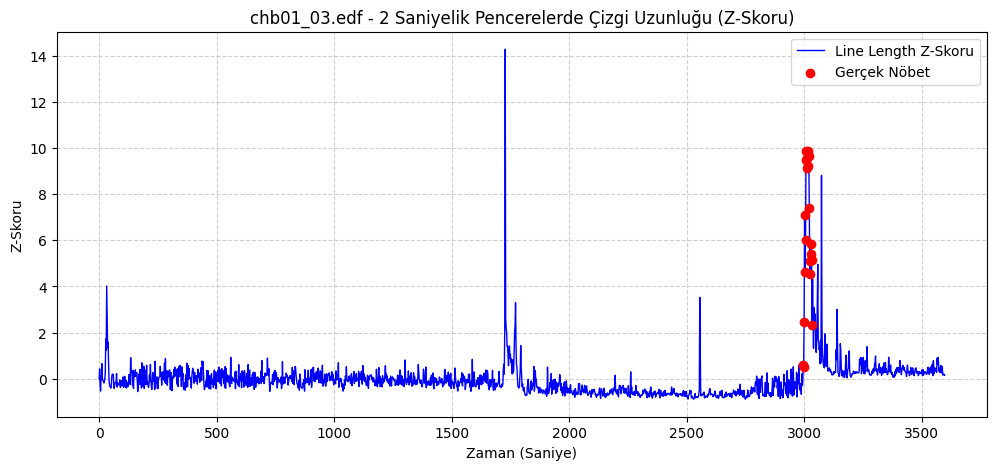

Z-skoru eklenmiş veri setinden ilk 5 satır:


,Hasta_Kayit,Pencere_No,Baslangic_Sn,Line_Length,Nobet_Durumu,Z_Score
0,chb01_03.edf,0,0,0.002649,0,-0.001886
1,chb01_03.edf,1,2,0.003088,0,0.425122
2,chb01_03.edf,2,4,0.002358,0,-0.285267
3,chb01_03.edf,3,6,0.002100,0,-0.536402
4,chb01_03.edf,4,8,0.002776,0,0.121010


In [3]:
import matplotlib.pyplot as plt

# 1. Z-Skoru Hesaplama (Her kayıt için kendi içinde)
# Z = (Değer - Ortalama) / Standart Sapma
df['Z_Score'] = df.groupby('Hasta_Kayit')['Line_Length'].transform(lambda x: (x - x.mean()) / x.std())

# 2. Şekil çizimi için ilk kaydı (chb01_03.edf) filtreleme
ornek_hasta = 'chb01_03.edf'
df_ornek = df[df['Hasta_Kayit'] == ornek_hasta]

# 3. Grafik (Şekil) figürünü oluşturma
plt.figure(figsize=(12, 5))

# 4. Z-skoru değerlerini zamana (saniye) göre mavi çizgi olarak çizdirme
plt.plot(df_ornek['Baslangic_Sn'], df_ornek['Z_Score'], label='Line Length Z-Skoru', color='blue', linewidth=1)

# 5. Nöbet anlarını (Nobet_Durumu == 1) bulup kırmızı noktalarla grafiğe ekleme
nobetler = df_ornek[df_ornek['Nobet_Durumu'] == 1]
plt.scatter(nobetler['Baslangic_Sn'], nobetler['Z_Score'], color='red', label='Gerçek Nöbet', zorder=5)

# 6. Grafiğin başlık, eksen isimleri ve ızgarasını ayarlama
plt.title(f"{ornek_hasta} - 2 Saniyelik Pencerelerde Çizgi Uzunluğu (Z-Skoru)")
plt.xlabel("Zaman (Saniye)")
plt.ylabel("Z-Skoru")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# 7. Grafiği ekranda gösterme
plt.show()

# 8. Z-skoru sütununun başarıyla eklendiğini görmek için ilk 5 satırı yazdırma
print("Z-skoru eklenmiş veri setinden ilk 5 satır:")
display(df.head())

In [4]:
from sklearn.metrics import f1_score

# 1. Hasta ID'lerini dosya adından çıkarma (chb01, chb02, chb03)
df['Hasta_ID'] = df['Hasta_Kayit'].apply(lambda x: x.split('_')[0])
hastalar = df['Hasta_ID'].unique()

# 2. Denenecek Z-skoru eşikleri (0'dan 20'ye kadar 0.1 adımlarla)
thresholds = np.arange(0, 20, 0.1)

print("--- Nöbet Tespiti F1 Skoru (Z-Skoru Eşikleme) ---")
genel_f1_listesi = []
iyimser_f1_listesi = []

# 3. Her hastayı sırayla test setine ayırma (Leave-One-Patient-Out)
for test_hasta in hastalar:
    # 4. Eğitim (diğer hastalar) ve Test (test hastası) verilerini ayır
    train_df = df[df['Hasta_ID'] != test_hasta]
    test_df = df[df['Hasta_ID'] == test_hasta]

    y_train_true = train_df['Nobet_Durumu']
    y_test_true = test_df['Nobet_Durumu']

    # 5. Eğitim verisinde F1'i en yüksek yapan 'genel eşiği' bulma
    best_train_f1, best_train_th = 0, 0
    for th in thresholds:
        y_pred = (train_df['Z_Score'] > th).astype(int)
        f1 = f1_score(y_train_true, y_pred, zero_division=0)
        if f1 > best_train_f1:
            best_train_f1, best_train_th = f1, th

    # 6. Test verisinin kendisinde F1'i en yüksek yapan 'iyimser eşiği' bulma
    best_test_f1, best_test_th = 0, 0
    for th in thresholds:
        y_pred = (test_df['Z_Score'] > th).astype(int)
        f1 = f1_score(y_test_true, y_pred, zero_division=0)
        if f1 > best_test_f1:
            best_test_f1, best_test_th = f1, th

    # 7. Diğer hastalardan bulduğumuz genel eşiği, görmediğimiz test hastasına uygulama
    y_test_pred_genel = (test_df['Z_Score'] > best_train_th).astype(int)
    f1_genel = f1_score(y_test_true, y_test_pred_genel, zero_division=0)

    genel_f1_listesi.append(f1_genel)
    iyimser_f1_listesi.append(best_test_f1)

    print(f"\nTest Hastası: {test_hasta}")
    print(f"  - Diğer hastalardan öğrenilen eşik: {best_train_th:.2f} -> Bu eşikle Genel F1: {f1_genel:.3f}")
    print(f"  - Hastanın kendine özel en iyi eşiği: {best_test_th:.2f} -> İyimser F1: {best_test_f1:.3f}")

# 8. Tüm hastalar için ortalama skorları yazdırma
print("\n=== SONUÇ (ORTALAMA) ===")
print(f"Ortalama Genel F1 (Gerçekçi Baseline): {np.mean(genel_f1_listesi):.3f}")
print(f"Ortalama İyimser F1 (Hastaya Özel Üst Sınır): {np.mean(iyimser_f1_listesi):.3f}")

--- Nöbet Tespiti F1 Skoru (Z-Skoru Eşikleme) ---

Test Hastası: chb01
  - Diğer hastalardan öğrenilen eşik: 1.80 -> Bu eşikle Genel F1: 0.590
  - Hastanın kendine özel en iyi eşiği: 4.40 -> İyimser F1: 0.821

Test Hastası: chb02
  - Diğer hastalardan öğrenilen eşik: 3.80 -> Bu eşikle Genel F1: 0.000
  - Hastanın kendine özel en iyi eşiği: 0.10 -> İyimser F1: 0.312

Test Hastası: chb03
  - Diğer hastalardan öğrenilen eşik: 4.40 -> Bu eşikle Genel F1: 0.233
  - Hastanın kendine özel en iyi eşiği: 2.00 -> İyimser F1: 0.424

=== SONUÇ (ORTALAMA) ===
Ortalama Genel F1 (Gerçekçi Baseline): 0.274
Ortalama İyimser F1 (Hastaya Özel Üst Sınır): 0.519
